## Transfer Learning with VGG19 for MNIST Digit Classification

In this notebook, we will use a pre-trained VGG19 model to classify digits from the MNIST dataset. We will leverage transfer learning to improve the performance of our model. Transfer learning involves using a pre-trained model on a new, but related task. This allows us to benefit from the features learned by the pre-trained model on a large dataset.

##### What is Transfer Learning?
Transfer learning is a machine learning technique where a model developed for a particular task is reused as the starting point for a model on a second task. It is particularly useful when the second task has a smaller dataset. The pre-trained model, which has already learned useful features from a large dataset, can be fine-tuned to perform well on the new task.

##### How VGG19 Enables Transfer Learning:

Pre-trained Weights: VGG19 is pre-trained on the ImageNet dataset, which contains millions of images across 1,000 classes. This extensive training allows VGG19 to learn rich feature representations.
Feature Extraction: By using the convolutional base of VGG19, we can extract these learned features and apply them to the MNIST dataset.
Fine-tuning: We can add and train new layers on top of the pre-trained base to adapt it to our specific task of digit classification.

##### Import Necessary Libraries

In [ ]:
import numpy as np
import cv2
from keras.datasets import mnist
from keras.utils import to_categorical
from keras.applications import VGG19
from keras.models import Model
from keras.layers import Dense, Flatten, Input, Dropout
from keras.optimizers import Adam
from tensorflow.keras.models import Sequential


#### Loading and Preprocessing the MNIST Dataset
The MNIST dataset contains 60,000 training images and 10,000 testing images of handwritten digits. Each image is 28x28 pixels in grayscale. We will preprocess the data by reshaping the images to include a channel dimension and normalizing the pixel values.

In [ ]:
# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Reshape to include channel dimension and normalize
x_train = x_train.reshape((x_train.shape[0], 28, 28, 1)).astype('float32') / 255
x_test = x_test.reshape((x_test.shape[0], 28, 28, 1)).astype('float32') / 255

# One-hot encode the labels
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


#### Make MNIST images compatable for VGG19 network
Why Change the Shape?
The default input size for VGG19 model is 224x224 and VGG16 expects 3 channels
1. Input Shape Compatibility: VGG19 expects input images of shape (224, 224, 3), which means the images should be 224x224 pixels with 3 color channels (RGB). However, MNIST images are 28x28 pixels with a single channel (grayscale).
1. Resizing: We need to resize the MNIST images from 28x28 to 224x224 to match the input size expected by VGG19.
1. Channel Conversion: Since VGG19 expects 3 channels, we need to convert the single-channel grayscale images to 3-channel images by stacking the grayscale image three times.

#### Convert Grayscale Images to RGB
VGG16 expects input images with 3 color channels (RGB). Since MNIST images are grayscale, we need to convert them to 3-channel images by stacking the grayscale image three times.

In [ ]:
# Convert grayscale images to RGB by stacking the single channel three times
x_train = np.concatenate([x_train, x_train, x_train], axis=-1)
x_test = np.concatenate([x_test, x_test, x_test], axis=-1)

#### Resize Images to 32x32
VGG16 expects input images of size 224x224 pixels. We need to resize the MNIST images from 28x28 to 224x224 pixels. But we can also use a less size image. So using here 32x32.

In [ ]:
#resize the images to 32x32
x_train_resized=np.array([cv2.resize(img, (32, 32)) for img in x_train])
x_test_resized=np.array([cv2.resize(img, (32,32)) for img in x_test])

##### Building the Model with VGG19
We will use the VGG19 model pre-trained on ImageNet as the base model. We will add a few fully connected layers on top of it to adapt it to the MNIST dataset.

#### Transfer Learning:

1. Pre-trained Model: VGG19 is pre-trained on the ImageNet dataset, which has a large and diverse set of images. This pre-training allows the model to learn a wide variety of features.
1. Feature Extraction: By using the convolutional base of VGG19, we can leverage these learned features for our new task. The convolutional layers of VGG19 act as a feature extractor.
1. Fine-tuning: We add new layers on top of the pre-trained base and train these layers on the MNIST dataset. This allows the model to adapt the learned features to the specific task of digit classification.


#### Load the VGG19 Model
We load the VGG19 model without the top layers (include_top=False) so that we can add our own custom layers for the classification task.

In [ ]:
# Load the VGG16 mode h
input_tensor = Input(shape=(32, 32, 3))
base_model = VGG19(weights='imagenet', include_top=False, input_tensor=input_tensor)

  # display the summary to see the properties of the model
base_model.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,024,384 (76.39 MB)

 Trainable params: 20,024,384 (76.39 MB)

 Non-trainable params: 0 (0.00 B)

#### Changes in the Model:

1. Freezing Layers: We freeze the layers of the pre-trained VGG19 model to retain the learned features and prevent them from being updated during training.
1. Adding New Layers: We add new fully connected layers on top of the pre-trained base. These layers are trained on the MNIST dataset to adapt the model to the new task.

In [ ]:

# Freeze the convolutional base
for layer in base_model.layers:
    layer.trainable = False

# Add custom layers on top of the base model
model = Sequential()
model.add(base_model)
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))

##### Compiling the Model
Next, we compile the model using the Adam optimizer, categorical cross-entropy loss function, and accuracy as a metric.

In [ ]:
model.compile(optimizer=Adam(), loss='categorical_crossentropy', metrics=['accuracy'])

##### Training the Model
We train the model using the training data. We set the number of epochs to 10 and the batch size to 128. We also use 20% of the training data for validation.

In [ ]:
history = model.fit(x_train_resized, y_train, epochs=10, batch_size=128, validation_split=0.2)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 42ms/step - accuracy: 0.6255 - loss: 1.1814 - val_accuracy: 0.9277 - val_loss: 0.2654
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.9046 - loss: 0.3294 - val_accuracy: 0.9513 - val_loss: 0.1749
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.9274 - loss: 0.2418 - val_accuracy: 0.9572 - val_loss: 0.1427
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.9405 - loss: 0.1975 - val_accuracy: 0.9621 - val_loss: 0.1246
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.9444 - loss: 0.1803 - val_accuracy: 0.9630 - val_loss: 0.1173
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.9496 - loss: 0.1655 - val_accuracy: 0.9647 - val_loss: 0.1122
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.9534 - loss: 0.1503 - val_accuracy: 0.9679 - val_loss: 0.1031
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.9539 - loss: 0.1445 - 

##### Evaluating the Model
After training, we evaluate the model on the test data to see how well it performs on unseen data.

In [ ]:
test_loss, test_acc = model.evaluate(x_test_resized, y_test)
print(f'Test accuracy: {test_acc}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9661 - loss: 0.1045
Test accuracy: 0.9704999923706055


#### Create a confusion matrix plot

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step


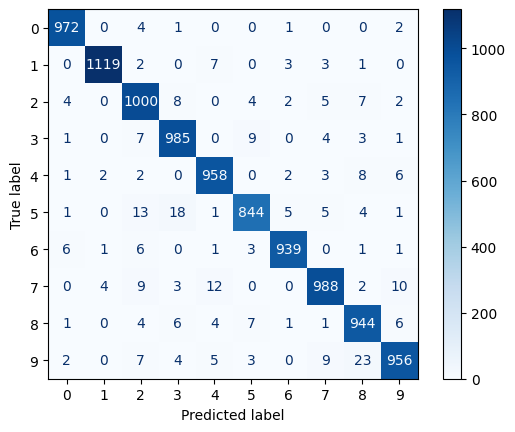

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming x_test_resized and y_test are your test data and true labels
y_pred = model.predict(x_test_resized)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()


##### Plotting Training History
Finally, we plot the training and validation accuracy over the epochs to visualize the model’s performance.

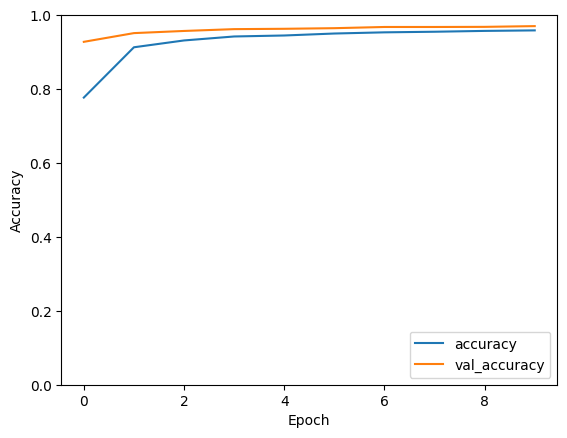

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.show()